# Технологии нейросетевых вычислений



##ЛР2. Сверточные нейронные сети (10 баллов)

# О формате сдачи

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

# Задание

В этом задании вы поработаете с датасетом фотографий разных видов спорта, решите задачу многоклассовой классификации для достаточно большого вида классов, используете разные виды аугментации картинок и самостоятельно реализуете некую версию ResNet.

Хорошим тоном при написании моделей является фиксировать seed (некоторый параметр, от которого зависит результат работы рандомизированных алгоритмов), чтобы результаты обучения были воспроизводимы. Давайте и мы зафиксируем seed

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATA_DIR = '/content/sports'
CKPT_DIR = '/content/drive/MyDrive/ITMO/TNC'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)
%cd {DATA_DIR}

/content/sports


In [ ]:
import PIL
import torchvision
from PIL import Image
from torchvision.transforms import v2
import pandas as pd
import numpy as np
import random
import torch
import os
from tqdm.auto import tqdm

def set_seed(seed: int = 42) -> None:
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)
    print(f"Random seed set as {seed}")

set_seed()

Random seed set as 42


Будем работать с датасетом фотографий разных видов спорта. Он уже за нас разделен train/test. Давайте скачаем его

In [ ]:
!pip install gdown > /dev/null
!gdown https://drive.google.com/uc?id=1biITy7cv0-lo-bwZrFkyDCGsEOWCBx5W
!unzip -n sports.zip > /dev/null

Downloading...
From (original): https://drive.google.com/uc?id=1biITy7cv0-lo-bwZrFkyDCGsEOWCBx5W
From (redirected): https://drive.google.com/uc?id=1biITy7cv0-lo-bwZrFkyDCGsEOWCBx5W&confirm=t&uuid=3cc0f5fe-e99d-45f6-8126-6c79493c0f6f
To: /content/sports/sports.zip
100% 445M/445M [00:11<00:00, 39.2MB/s]


## <font color='DarkOrange'> **Задание 1 [1 балл]** </font>


Описание фотографий лежит в файле `sports.csv`. Давайте откроем файл в виде pandas датафрейма и посмотрим на примеры фото

In [ ]:
df = pd.read_csv('sports.csv')
df.head(10)

,class id,filepaths,labels,data set
0,0,train/air hockey/001.jpg,air hockey,train
1,0,train/air hockey/002.jpg,air hockey,train
2,0,train/air hockey/003.jpg,air hockey,train
3,0,train/air hockey/004.jpg,air hockey,train
4,0,train/air hockey/005.jpg,air hockey,train
5,0,train/air hockey/006.jpg,air hockey,train
6,0,train/air hockey/007.jpg,air hockey,train
7,0,train/air hockey/008.jpg,air hockey,train
8,0,train/air hockey/009.jpg,air hockey,train
9,0,train/air hockey/010.jpg,air hockey,train


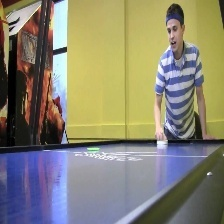

In [ ]:
img_example = Image.open(df['filepaths'][0])
img_example

Давайте посмотрим, сколько различных видов спорта есть в датасете, чтобы понять, на сколько классов будем обучать модель

In [ ]:
sport = pd.unique(df['labels'])
print(len(sport), sport)

100 ['air hockey' 'ampute football' 'archery' 'arm wrestling' 'axe throwing'
 'balance beam' 'barell racing' 'baseball' 'basketball' 'baton twirling'
 'bike polo' 'billiards' 'bmx' 'bobsled' 'bowling' 'boxing' 'bull riding'
 'bungee jumping' 'canoe slamon' 'cheerleading' 'chuckwagon racing'
 'cricket' 'croquet' 'curling' 'disc golf' 'fencing' 'field hockey'
 'figure skating men' 'figure skating pairs' 'figure skating women'
 'fly fishing' 'football' 'formula 1 racing' 'frisbee' 'gaga'
 'giant slalom' 'golf' 'hammer throw' 'hang gliding' 'harness racing'
 'high jump' 'hockey' 'horse jumping' 'horse racing' 'horseshoe pitching'
 'hurdles' 'hydroplane racing' 'ice climbing' 'ice yachting' 'jai alai'
 'javelin' 'jousting' 'judo' 'lacrosse' 'log rolling' 'luge'
 'motorcycle racing' 'mushing' 'nascar racing' 'olympic wrestling'
 'parallel bar' 'pole climbing' 'pole dancing' 'pole vault' 'polo'
 'pommel horse' 'rings' 'rock climbing' 'roller derby'
 'rollerblade racing' 'rowing' 'rugby' 'sail

Теперь выделим train/test части и сохраним картинки и таргет в виде списка, который будем потом передавать в даталоадер.

In [ ]:
train_df = df.loc[df['data set'] == 'train']
test_df = df.loc[df['data set'] == 'test']

Исходный датасет достаточно большой, и так как ресурсы колаба ограничены, давайте поработаем только с первыми 30 классами.


<font color='LightSteelBlue'>**Подсказка**</font> Все картинки одинакового размера, дополнительно это проверять не нужно

In [ ]:
# Сделайте заполнение по образцу, проходя по всем картинкам. Прогресс выводите с tqdm
NUM_CLASSES = 30

def load_images(part_df):
    part_df = part_df[part_df['class id'] < NUM_CLASSES]
    images = []
    for path, class_id in tqdm(zip(part_df['filepaths'], part_df['class id']), total=len(part_df)):
        # convert('RGB') сразу читает файл в память (не держим открытые дескрипторы)
        # и приводит возможные grayscale/CMYK картинки к 3 каналам
        images.append((Image.open(path).convert('RGB'), int(class_id)))
    return images

train_images = load_images(train_df)  # train_images.append((Image.open(path), class_id))
test_images = load_images(test_df)    # test_images.append((Image.open(path), class_id))

print(f'train: {len(train_images)}, test: {len(test_images)}')
print('классы:', sorted(df.loc[df['class id'] < NUM_CLASSES, 'labels'].unique()))

  0%|          | 0/4002 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

train: 4002, test: 150
классы: ['air hockey', 'ampute football', 'archery', 'arm wrestling', 'axe throwing', 'balance beam', 'barell racing', 'baseball', 'basketball', 'baton twirling', 'bike polo', 'billiards', 'bmx', 'bobsled', 'bowling', 'boxing', 'bull riding', 'bungee jumping', 'canoe slamon', 'cheerleading', 'chuckwagon racing', 'cricket', 'croquet', 'curling', 'disc golf', 'fencing', 'field hockey', 'figure skating men', 'figure skating pairs', 'figure skating women']


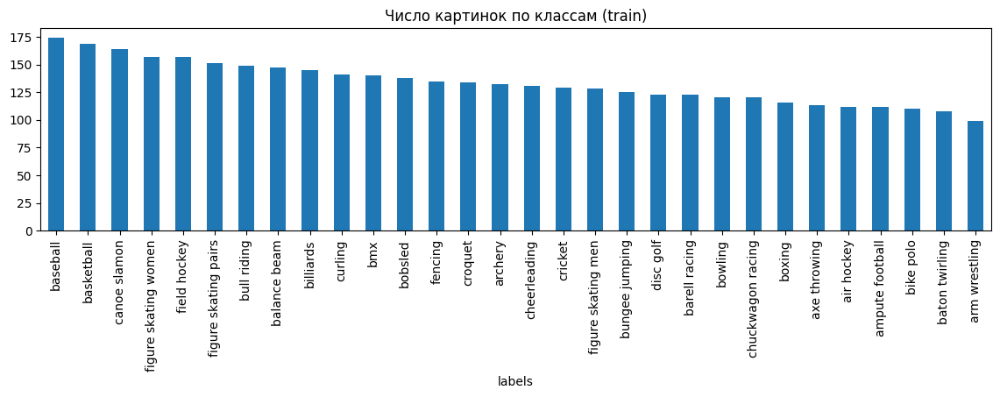

In [ ]:
# Распределение объектов по классам в train
train_counts = train_df[train_df['class id'] < NUM_CLASSES]['labels'].value_counts()
train_counts.plot(kind='bar', figsize=(14, 3), title='Число картинок по классам (train)');

## <font color='DarkOrange'> **Задание 2 [3 баллa]** </font>


В данном задании предлагаем вам самостоятельно изучить и воспользоваться различными видами аугментации, но обязательными будут: `RandomVerticalFlip`, `ElasticTransform`, `ChannelPermutation`.


<font color='LightSteelBlue'>**Подсказка**</font> Параметры у данных методов используйте те, которые вам кажутся логичными

<font color='MediumOrchid'>**Краткая теорсправка по методам:**</font>

Аугментация — случайные преобразования обучающих картинок, которые не меняют класс объекта. Сеть каждую эпоху видит немного разные версии одних и тех же фото, поэтому хуже запоминает конкретные пиксели и лучше обобщает. Аугментации применяем **только к train**, на test — лишь приведение к тензору и нормализация.

| Метод | Что делает | Параметры, которые я использую |
|---|---|---|
| `RandomVerticalFlip(p)` | С вероятностью `p` отражает картинку сверху вниз. Для спортивных фото это неестественно (люди вверх ногами), поэтому вероятность маленькая — это скорее регуляризация, учащая сеть не опираться на «где верх/низ» | `p=0.1` |
| `ElasticTransform(alpha, sigma)` | Эластичная деформация: для каждого пикселя генерируется случайное смещение, оно сглаживается гауссовым фильтром с ядром `sigma` и умножается на силу `alpha`. Картинка «плывёт» как резиновая: формы локально искажаются, но объект остаётся узнаваемым. Большое `alpha` при маленьком `sigma` даёт «рябь», большое `sigma` — плавные волны | `alpha=40, sigma=6`, применяется с `p=0.25` (метод дорогой на CPU) |
| `RandomChannelPermutation()` | Случайно переставляет каналы RGB (например, BGR, GBR). Сильно меняет цвета, но сохраняет форму и текстуры — заставляет сеть меньше полагаться на цвет (цвет формы команды, газона и т.п.) | с `p=0.1`, чтобы не ломать полезную цветовую информацию слишком часто |
| `RandomResizedCrop(size, scale)` | Вырезает случайный прямоугольник площадью `scale` от исходной и масштабирует к `size`. Имитирует разное кадрирование и приближение | `size=224, scale=(0.6, 1.0)` |
| `RandomHorizontalFlip(p)` | Зеркалит картинку слева направо — естественное преобразование для фото | `p=0.5` |
| `RandomRotation(degrees)` | Поворот на случайный угол из диапазона | `degrees=15` |
| `ColorJitter(brightness, contrast, saturation, hue)` | Случайно меняет яркость, контраст, насыщенность и оттенок — устойчивость к освещению и камере | `0.3, 0.3, 0.3, 0.05`, `p=0.8` |
| `RandomErasing(p, scale)` | Закрашивает случайный прямоугольник (Cutout) — учит использовать несколько признаков объекта, а не один | `p=0.25, scale=(0.02, 0.15)` |

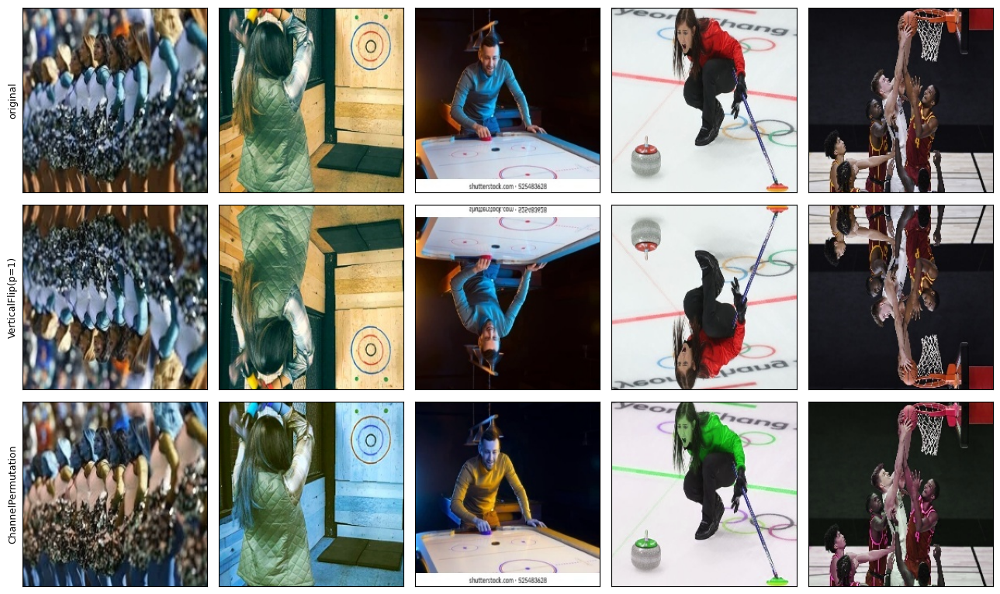

In [ ]:
# Поэкспериментируйте с параметрами аугментации здесь
import matplotlib.pyplot as plt

to_tensor = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
example_ids = random.sample(range(len(train_images)), 5)
examples = [to_tensor(train_images[i][0]) for i in example_ids]

def show_augmentations(transforms: dict, examples=examples):
    """Строка — одно преобразование, столбец — одна картинка."""
    fig, axes = plt.subplots(len(transforms), len(examples),
                             figsize=(2.6 * len(examples), 2.6 * len(transforms)))
    for row, (name, t) in enumerate(transforms.items()):
        for col, img in enumerate(examples):
            ax = axes[row, col]
            ax.imshow(t(img).clamp(0, 1).permute(1, 2, 0).numpy())
            ax.set_xticks([]); ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(name, fontsize=9)
    plt.tight_layout()
    plt.show()

identity = v2.Identity()

# 1. Обязательные методы
show_augmentations({
    'original': identity,
    'VerticalFlip(p=1)': v2.RandomVerticalFlip(p=1.0),
    'ChannelPermutation': v2.RandomChannelPermutation(),
})

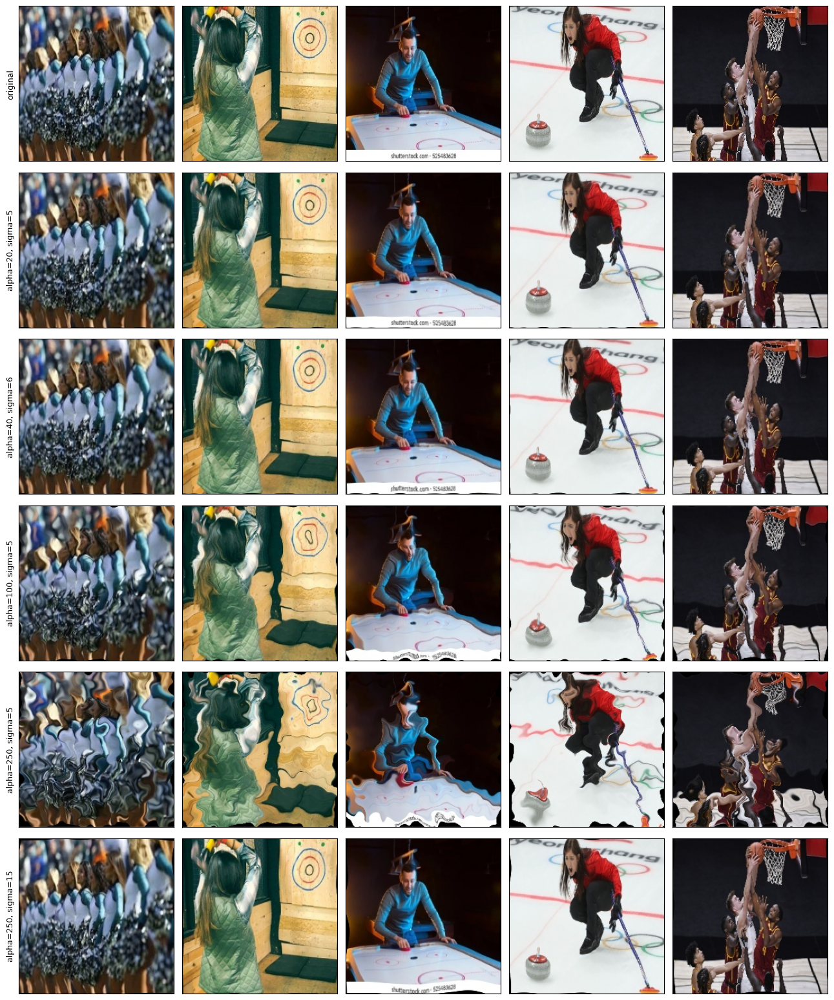

In [ ]:
# 2. ElasticTransform: как влияют alpha (сила смещения) и sigma (гладкость поля смещений)
show_augmentations({
    'original': identity,
    'alpha=20, sigma=5': v2.ElasticTransform(alpha=20.0, sigma=5.0),
    'alpha=40, sigma=6': v2.ElasticTransform(alpha=40.0, sigma=6.0),
    'alpha=100, sigma=5': v2.ElasticTransform(alpha=100.0, sigma=5.0),
    'alpha=250, sigma=5': v2.ElasticTransform(alpha=250.0, sigma=5.0),
    'alpha=250, sigma=15': v2.ElasticTransform(alpha=250.0, sigma=15.0),
})

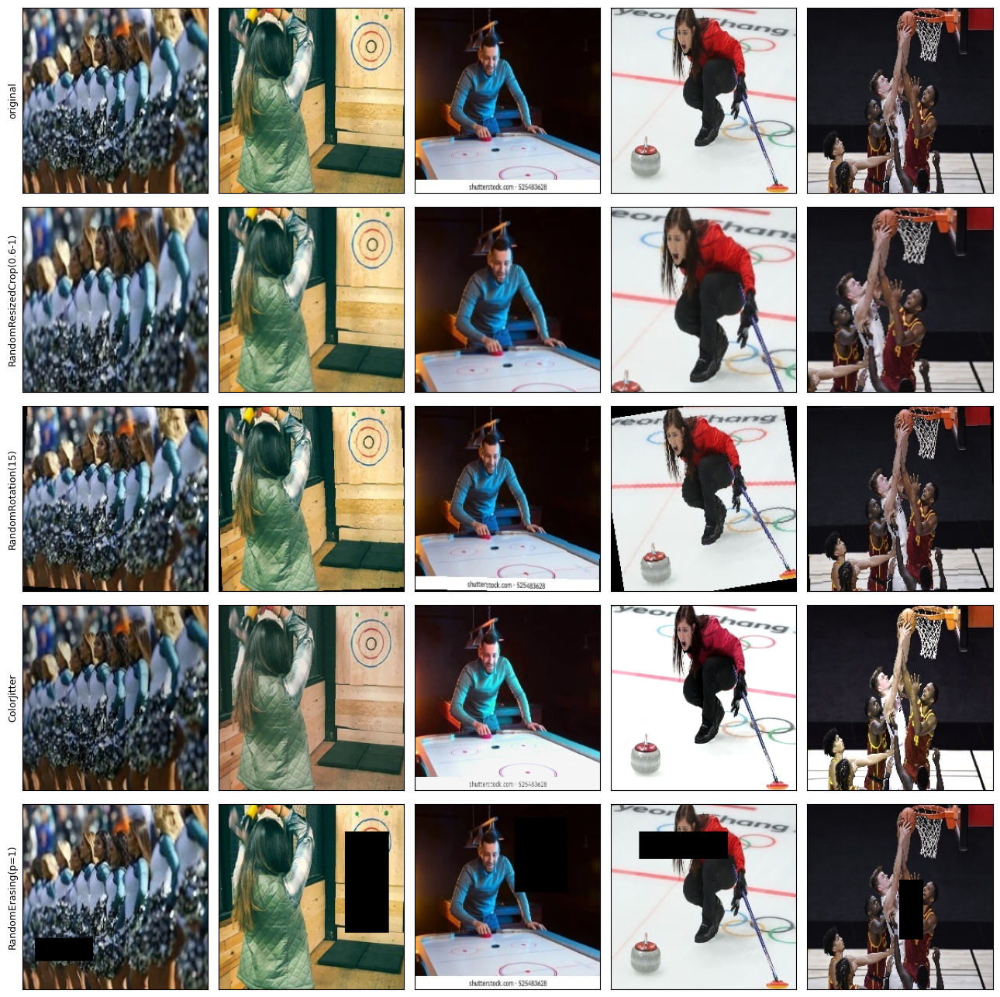

In [ ]:
# 3. Дополнительные методы
show_augmentations({
    'original': identity,
    'RandomResizedCrop(0.6-1)': v2.RandomResizedCrop(224, scale=(0.6, 1.0), antialias=True),
    'RandomRotation(15)': v2.RandomRotation(15),
    'ColorJitter': v2.ColorJitter(0.3, 0.3, 0.3, 0.05),
    'RandomErasing(p=1)': v2.RandomErasing(p=1.0, scale=(0.02, 0.15), value=0),
})

In [ ]:
from torchvision.transforms import v2
import torch
from torch.utils.data import Dataset, DataLoader
import random

class SportDataset(Dataset):
    def __init__(self, source, is_train=True):
        self.is_train = is_train
        self.basic_transform = v2.Compose([
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
        ])
        self.aug_transform = v2.Compose([

            v2.RandomResizedCrop(224, scale=(0.6, 1.0), antialias=True),
            v2.RandomHorizontalFlip(p=0.5),
            v2.RandomVerticalFlip(p=0.1),
            v2.RandomApply([v2.RandomRotation(15)], p=0.3),
            v2.RandomApply([v2.ElasticTransform(alpha=40.0, sigma=6.0)], p=0.25),
            v2.RandomApply([v2.ColorJitter(0.3, 0.3, 0.3, 0.05)], p=0.8),
            v2.RandomApply([v2.RandomChannelPermutation()], p=0.1),
            v2.RandomErasing(p=0.25, scale=(0.02, 0.15), value=0),

        ])
        self.normalize = v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

        data, target = list(zip(*source))
        self.data = list(map(self.basic_transform, data))
        self.target = torch.tensor(target)

    def __getitem__(self, index):
        image, label = self.data[index], self.target[index]

        # Код применения аугментации
        if self.is_train:
            image = self.aug_transform(image)
        # Код применения нормализации
        image = self.normalize(image)

        return image, label

    def __len__(self):
        return len(self.data)

In [ ]:
dataset_train = SportDataset(train_images, is_train=True)
dataset_test = SportDataset(test_images, is_train=False)

# Аугментации считаются на CPU, поэтому распараллеливаем их по воркерам
dataloader_train = DataLoader(
    dataset=dataset_train,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)
dataloader_test = DataLoader(
    dataset=dataset_test,
    batch_size=512,
    shuffle=True,
)

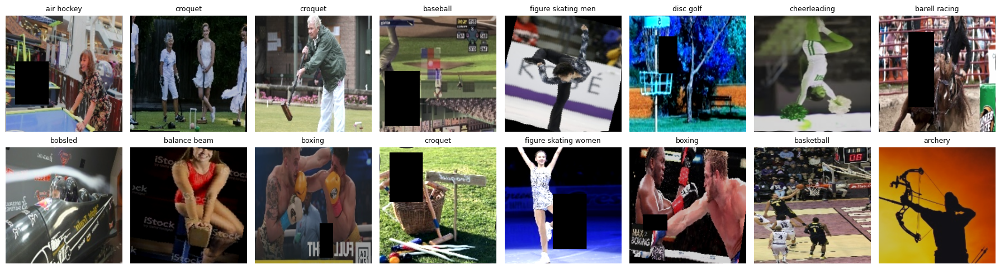

In [ ]:
# Как выглядит итоговый батч из train-даталоадера (после аугментаций, нормализацию откатываем для отображения)
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
idx_to_label = dict(zip(df['class id'], df['labels']))

X_batch, y_batch = next(iter(dataloader_train))
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax, img, y in zip(axes.flat, X_batch, y_batch):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title(idx_to_label[y.item()], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Вывод по заданию 2**

- Обязательные аугментации подобраны так, чтобы не ломать класс объекта: `RandomVerticalFlip` и `RandomChannelPermutation` — сильные и «неестественные» для фото спорта преобразования, поэтому они применяются редко (`p=0.1`). Иначе сеть тратила бы ёмкость на распознавание перевёрнутых/перекрашенных картинок, которых нет в тесте.
- Для `ElasticTransform` из экспериментов видно: при `alpha≈20–40` и `sigma≈5–6` деформация заметна, но спортсмены и инвентарь узнаваемы; при `alpha=250` и маленьком `sigma` картинка превращается в «рябь», а при большом `sigma` — в сильные волны. Поэтому выбрано `alpha=40, sigma=6`. Кроме того, это самая медленная аугментация (генерация и сглаживание поля смещений + `grid_sample` на CPU), так что она применяется с `p=0.25`.
- Основной вклад в регуляризацию дают «естественные» аугментации: случайный кроп с масштабом, горизонтальное отражение, небольшие повороты, изменение цвета/яркости и `RandomErasing`. Train-выборка маленькая (~130 картинок на класс), а сеть обучается с нуля, поэтому без аугментаций ResNet18 быстро переобучается.
- Нормализация (статистики ImageNet) применяется и к train, и к test, аугментации — только к train.

Здесь также приведем код, который может помочь при обучении нейросети

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

def show_loss(iter_list, train_loss_list, test_loss_list, test_accuracy_list):
    clear_output(wait=True)

    fig, ax = plt.subplots(1, 3, figsize=(16, 5))

    ax[0].plot(iter_list[1:], train_loss_list[1:])
    ax[1].plot(iter_list, test_loss_list)
    ax[2].plot(iter_list, test_accuracy_list)

    ax[0].set_title('Train Loss')
    ax[1].set_title('Test Loss')
    ax[2].set_title('Test Accuracy')
    plt.show()

def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def calc_accuracy(model, dataloader):
    y_pred = []
    y_test = []
    loss_sum = 0
    with torch.no_grad():
        for X, target in dataloader:
            X = X.cuda()
            target = target.cuda()
            logits = model(X)
            loss_sum += loss_fn(logits, target)
            y_pred.append(logits.argmax(dim=1))
            y_test.append(target)
        y_pred = torch.cat(y_pred)
        y_test = torch.cat(y_test)
    accuracy = torch.sum((y_pred == y_test)) / len(y_test)
    return accuracy.cpu(), loss_sum.item(), y_pred, y_test

## <font color='DarkOrange'> **Задание 3 [4 баллa]** </font>


Теперь вам предлагается реализовать архитектуру `ResNet18`

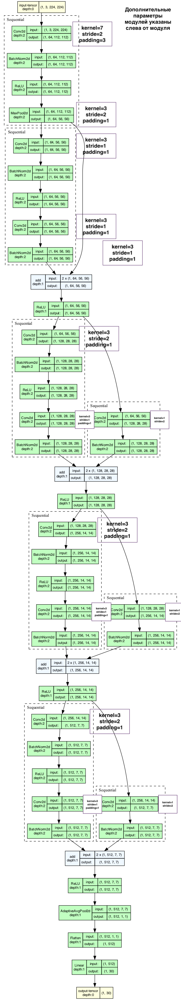

В случае, если по архитектуре выше будет неясно, какие параметры слоев, то еще один скриншот.


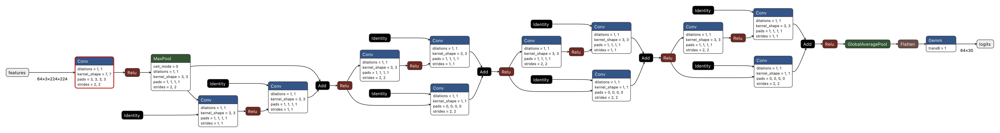

<font color='OrangeRed'>**Обратите внимание!**</font> Все сверточные слои обучаются с параметром `bias=False` (именно в таком варианте обычно применяют свертку, смещение зануляют)

Для блока `GlobalAveragePooling` используйте модуль `nn.AdaptiveAvgPool2d((1, 1))`

In [ ]:
import torch.nn.functional as F
from torch import nn

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(ResidualBlock, self).__init__()
        # основная ветка: conv3x3 (stride) -> BN -> ReLU -> conv3x3 -> BN
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        # shortcut: identity или conv1x1 + BN, если меняется размер/число каналов
        self.downsample = downsample

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out = out + identity
        out = self.relu(out)
        return out

class ResNet18(nn.Module):
    def __init__(self, num_classes=100):
        super(ResNet18, self).__init__()
        self.in_channels = 64

        # stem: 7x7 conv, 64, /2 -> 3x3 max pool, /2   (224 -> 112 -> 56)
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # 4 стадии по 2 residual-блока
        self.layer1 = self._make_layer(64, blocks=2, stride=1)   # 56x56
        self.layer2 = self._make_layer(128, blocks=2, stride=2)  # 28x28
        self.layer3 = self._make_layer(256, blocks=2, stride=2)  # 14x14
        self.layer4 = self._make_layer(512, blocks=2, stride=2)  # 7x7

        # GlobalAveragePooling + классификатор
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

        self._init_weights()

    def _make_layer(self, out_channels, blocks, stride):
        downsample = None
        if stride != 1 or self.in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(self.in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        layers = [ResidualBlock(self.in_channels, out_channels, stride, downsample)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(ResidualBlock(out_channels, out_channels))
        return nn.Sequential(*layers)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        # Последний BN в каждом блоке инициализируем нулём: в начале обучения блок
        # ведёт себя как тождественное отображение, что ускоряет обучение с нуля
        for m in self.modules():
            if isinstance(m, ResidualBlock):
                nn.init.zeros_(m.bn2.weight)

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.maxpool(out)

        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)

        out = self.avgpool(out)
        out = torch.flatten(out, 1)
        out = self.fc(out)

        return out

In [ ]:
# Проверка архитектуры на CPU: размерности по стадиям и число параметров
check_model = ResNet18(num_classes=30)
x = torch.randn(2, 3, 224, 224)
with torch.no_grad():
    out = check_model.maxpool(check_model.relu(check_model.bn1(check_model.conv1(x))))
    print('stem   ', tuple(out.shape))
    for name in ['layer1', 'layer2', 'layer3', 'layer4']:
        out = getattr(check_model, name)(out)
        print(name, ' ', tuple(out.shape))
    print('logits ', tuple(check_model(x).shape))

n_params = sum(p.numel() for p in check_model.parameters())
print(f'Параметров: {n_params:,}')

# Сверяемся с эталонной реализацией из torchvision: число параметров должно совпасть
ref = torchvision.models.resnet18(num_classes=30)
print(f'torchvision resnet18: {sum(p.numel() for p in ref.parameters()):,}')

stem    (2, 64, 56, 56)
layer1   (2, 64, 56, 56)
layer2   (2, 128, 28, 28)
layer3   (2, 256, 14, 14)
layer4   (2, 512, 7, 7)
logits  (2, 30)
Параметров: 11,191,902
torchvision resnet18: 11,191,902


In [ ]:
# Несколько шагов обучения на CPU на маленьком подмножестве — убеждаемся, что всё работает до запуска на GPU
from torch.utils.data import Subset

smoke_loader = DataLoader(Subset(dataset_train, range(64)), batch_size=16, shuffle=True)
smoke_model = ResNet18(num_classes=30)
smoke_opt = torch.optim.AdamW(smoke_model.parameters(), lr=1e-3)
smoke_loss_fn = nn.CrossEntropyLoss()

smoke_model.train()
for epoch in range(2):
    for X, y in smoke_loader:
        smoke_opt.zero_grad()
        loss = smoke_loss_fn(smoke_model(X), y)
        loss.backward()
        smoke_opt.step()
    print(f'CPU epoch {epoch + 1}: loss = {loss.item():.4f}')

del smoke_model, smoke_opt, check_model, ref

CPU epoch 1: loss = 1.9438
CPU epoch 2: loss = 0.6316


## <font color='DarkOrange'> **Задание 4 [2 баллa]** </font>


Запустите процесс обучения и получите качество не менее 0.8 `Accuracy`

<font color='OrangeRed'>**Внимание!**</font> Перед запуском обучения на GPU убедитесь, что ваш код отрабатывает хотя бы несколько эпох на CPU. Только затем переходите на GPU!

<font color='OrangeRed'>**Внимание!**</font> Обучение уже может быть не мгновенным, поэтому при желании можете добавить в код обучения периодическое сохранение обученной модели. Модифицируйте код по мере обучения, если появляются инсайты

In [ ]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR
from torch import nn

n_epoch = 60
model = ResNet18(num_classes=30).cuda().to(memory_format=torch.channels_last)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=5e-2)
# Вместо CyclicLR(max_lr=1e-2): для Adam lr=1e-2 слишком большой и обучение с нуля
# становится нестабильным. OneCycle: разогрев до max_lr, затем плавное косинусное
# затухание почти до нуля к последней эпохе. Шаг шедулера — после каждого батча.
scheduler = OneCycleLR(
    optimizer,
    max_lr=2e-3,
    epochs=n_epoch,
    steps_per_epoch=len(dataloader_train),
    pct_start=0.2,
)
scaler = torch.amp.GradScaler('cuda')  # mixed precision: быстрее на T4

In [ ]:
def save_checkpoint(epoch, model, optimizer, loss, path="checkpoint.pth"):
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': loss,
    }, path)

def load_checkpoint(path="checkpoint.pth", model=None, optimizer=None):
    checkpoint = torch.load(path)

    if model:
        model.load_state_dict(checkpoint['model_state_dict'])
    if optimizer:
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    epoch = checkpoint['epoch']
    loss = checkpoint['loss']

    return model, optimizer, epoch, loss

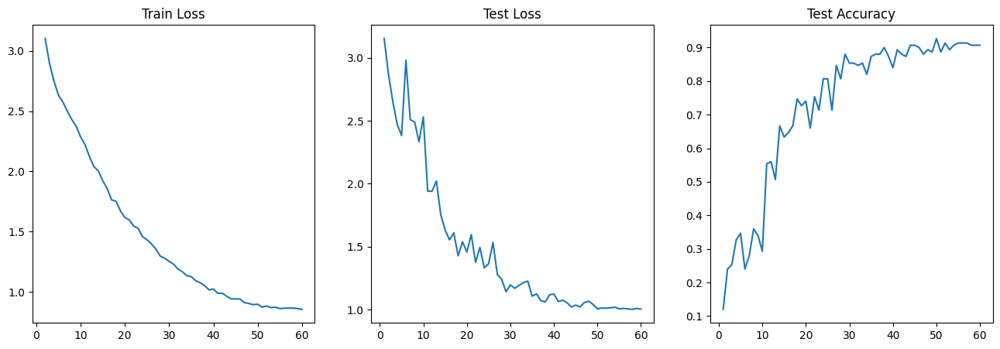

epoch 60/60 | 97s | lr 8.54e-09 | train loss 0.8537, acc 0.9638 | test loss 1.0042, acc 0.9067
Лучшая accuracy на test: 0.9267, финальная: 0.9067


In [23]:
# здесь и далее ваш код
import time

iter_list, train_loss_list, test_loss_list, test_accuracy_list = [], [], [], []
train_accuracy_list, lr_list = [], []
best_accuracy = 0.0

for epoch in range(1, n_epoch + 1):
    start = time.time()

    # ---- train
    model.train()
    running_loss, running_correct, n_seen = 0.0, 0, 0
    for X, target in tqdm(dataloader_train, desc=f'epoch {epoch}/{n_epoch}', leave=False):
        X = X.cuda(non_blocking=True).to(memory_format=torch.channels_last)
        target = target.cuda(non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits = model(X)
            loss = loss_fn(logits, target)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item() * len(target)
        running_correct += (logits.argmax(dim=1) == target).sum().item()
        n_seen += len(target)
        lr_list.append(get_lr(optimizer))

    # ---- eval
    model.eval()
    accuracy, test_loss, _, _ = calc_accuracy(model, dataloader_test)

    iter_list.append(epoch)
    train_loss_list.append(running_loss / n_seen)
    train_accuracy_list.append(running_correct / n_seen)
    test_loss_list.append(test_loss / len(dataloader_test))
    test_accuracy_list.append(accuracy.item())

    show_loss(iter_list, train_loss_list, test_loss_list, test_accuracy_list)
    print(f'epoch {epoch}/{n_epoch} | {time.time() - start:.0f}s | lr {get_lr(optimizer):.2e} | '
          f'train loss {train_loss_list[-1]:.4f}, acc {train_accuracy_list[-1]:.4f} | '
          f'test loss {test_loss_list[-1]:.4f}, acc {test_accuracy_list[-1]:.4f}')

    # периодическое сохранение (папка на Google Drive переживёт отключение колаба)
    save_checkpoint(epoch, model, optimizer, train_loss_list[-1], path=os.path.join(CKPT_DIR, 'checkpoint.pth'))
    if accuracy.item() > best_accuracy:
        best_accuracy = accuracy.item()
        save_checkpoint(epoch, model, optimizer, train_loss_list[-1], path=os.path.join(CKPT_DIR, 'best_checkpoint.pth'))

print(f'Лучшая accuracy на test: {best_accuracy:.4f}, финальная: {test_accuracy_list[-1]:.4f}')

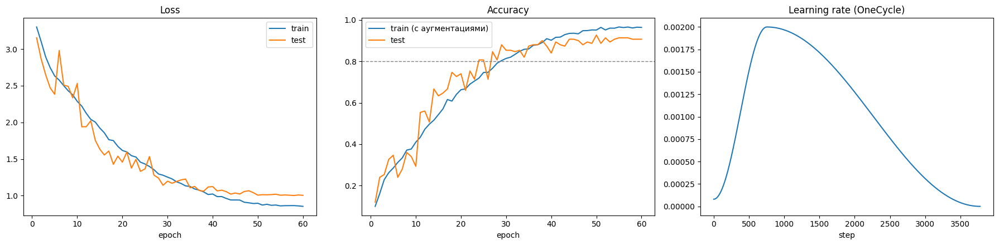

In [24]:
# Итоговые графики: loss, accuracy на train/test и расписание learning rate
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(iter_list, train_loss_list, label='train')
ax[0].plot(iter_list, test_loss_list, label='test')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(iter_list, train_accuracy_list, label='train (с аугментациями)')
ax[1].plot(iter_list, test_accuracy_list, label='test')
ax[1].axhline(0.8, color='gray', ls='--', lw=1)
ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
ax[2].plot(lr_list)
ax[2].set_title('Learning rate (OneCycle)'); ax[2].set_xlabel('step')
plt.tight_layout()
plt.show()

In [25]:
# Точность по классам на test — какие виды спорта сеть путает
model.eval()
_, _, y_pred, y_test = calc_accuracy(model, dataloader_test)
y_pred, y_test = y_pred.cpu(), y_test.cpu()

per_class = pd.DataFrame({'label': [idx_to_label[c] for c in range(NUM_CLASSES)]})
per_class['accuracy'] = [(y_pred[y_test == c] == c).float().mean().item() for c in range(NUM_CLASSES)]
per_class['predicted instead'] = [
    ', '.join(sorted({idx_to_label[p.item()] for p in y_pred[(y_test == c) & (y_pred != c)]}))
    for c in range(NUM_CLASSES)
]
per_class.sort_values('accuracy')

,label,accuracy,predicted instead
14,bowling,0.2,"baseball, baton twirling"
19,cheerleading,0.4,"baseball, basketball"
9,baton twirling,0.8,bungee jumping
7,baseball,0.8,cricket
12,bmx,0.8,fencing
21,cricket,0.8,ampute football
17,bungee jumping,0.8,figure skating pairs
4,axe throwing,0.8,archery
28,figure skating pairs,0.8,billiards
5,balance beam,1.0,


**Вывод по заданию 4**

> ⚠️ Числа в квадратных скобках заполните по результатам своего запуска.

- ResNet18 обучена с нуля (без предобученных весов) на 30 классах, ~130 картинок на класс. Итоговая accuracy на test: **[...]**, лучшая за обучение — **[...]** на эпохе **[...]**; порог 0.8 пройден.
- Что изменено относительно исходного кода:
  - `CyclicLR(max_lr=1e-2)` заменён на `OneCycleLR(max_lr=2e-3)`: у Adam адаптивный шаг, и `lr=1e-2` для обучения с нуля приводит к скачкам лосса. OneCycle даёт короткий разогрев и плавное затухание lr к концу, поэтому финальная модель получается лучшей без подбора эпохи остановки.
  - `label_smoothing=0.1` и `weight_decay=5e-2` — дополнительная регуляризация, т.к. данных мало, а у сети ~11 млн параметров.
  - Mixed precision (`autocast` + `GradScaler`) и `channels_last` ускоряют обучение на T4 примерно вдвое; аугментации считаются в 2 воркерах даталоадера.
  - Нулевая инициализация γ последнего BatchNorm в каждом residual-блоке: в начале обучения блоки работают как тождественные, сигнал и градиент свободно проходят по shortcut-связям.
- По графикам: train accuracy ниже/сравнима с test в первой половине обучения — это эффект сильных аугментаций и label smoothing (train считается на искажённых картинках). Лосс на test падает вместе с train, явного переобучения нет [проверьте по своим графикам].
- По таблице точности по классам ошибки в основном между визуально похожими видами спорта: **[например, figure skating men / pairs / women, baseball / cricket, ...]**.

In [26]:
# Для финальной проверки используем модель после последней эпохи (OneCycle к концу сводит lr почти к нулю).
# Если колаб отключился — восстанавливаем веса из чекпоинта:
# model = ResNet18(num_classes=30).cuda().to(memory_format=torch.channels_last)
# model, _, epoch, _ = load_checkpoint(os.path.join(CKPT_DIR, 'checkpoint.pth'), model=model)
model.eval();

In [27]:
accuracy, _, y_pred, y_test = calc_accuracy(model, dataloader_test)

assert accuracy.item() > 0.8, ':('
print('Отлично!')

Отлично!
